# 文埋め込みを PCA・t-SNE・UMAP で 2 次元に可視化して比べる

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/10_sentence_embeddings/embedding_visualization.ipynb)

NLP クックブック 10-05 ／ 文埋め込みとクラスタリング

文の埋め込みベクトルを散布図にして、データセットの全体像（クラスの分かれ方、外れ値）を眺めたい。次元削減の手法による見え方の違いも知りたい。

In [1]:
!pip install -q umap-learn matplotlib-fontja

In [2]:
import io, tarfile, urllib.request
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

def load_livedoor():
    url = "https://www.rondhuit.com/download/ldcc-20140209.tar.gz"
    with urllib.request.urlopen(url) as r:
        tar = tarfile.open(fileobj=io.BytesIO(r.read()), mode="r:gz")
    rows = []
    for m in tar.getmembers():
        parts = m.name.split("/")
        if m.isfile() and len(parts) == 3 and parts[2] != "LICENSE.txt":
            lines = tar.extractfile(m).read().decode("utf-8").split("\n")
            rows.append({"label": parts[1], "title": lines[2], "text": "\n".join(lines[3:])})
    return pd.DataFrame(rows)

df = load_livedoor()
df = df[df["label"].isin(["sports-watch", "movie-enter", "smax", "dokujo-tsushin", "kaden-channel"])]
df = df.groupby("label").sample(200, random_state=0).reset_index(drop=True)
model = SentenceTransformer("intfloat/multilingual-e5-small")
emb = model.encode(["query: " + t for t in df["title"]], normalize_embeddings=True, batch_size=64, show_progress_bar=False)
print(emb.shape)

(1000, 384)


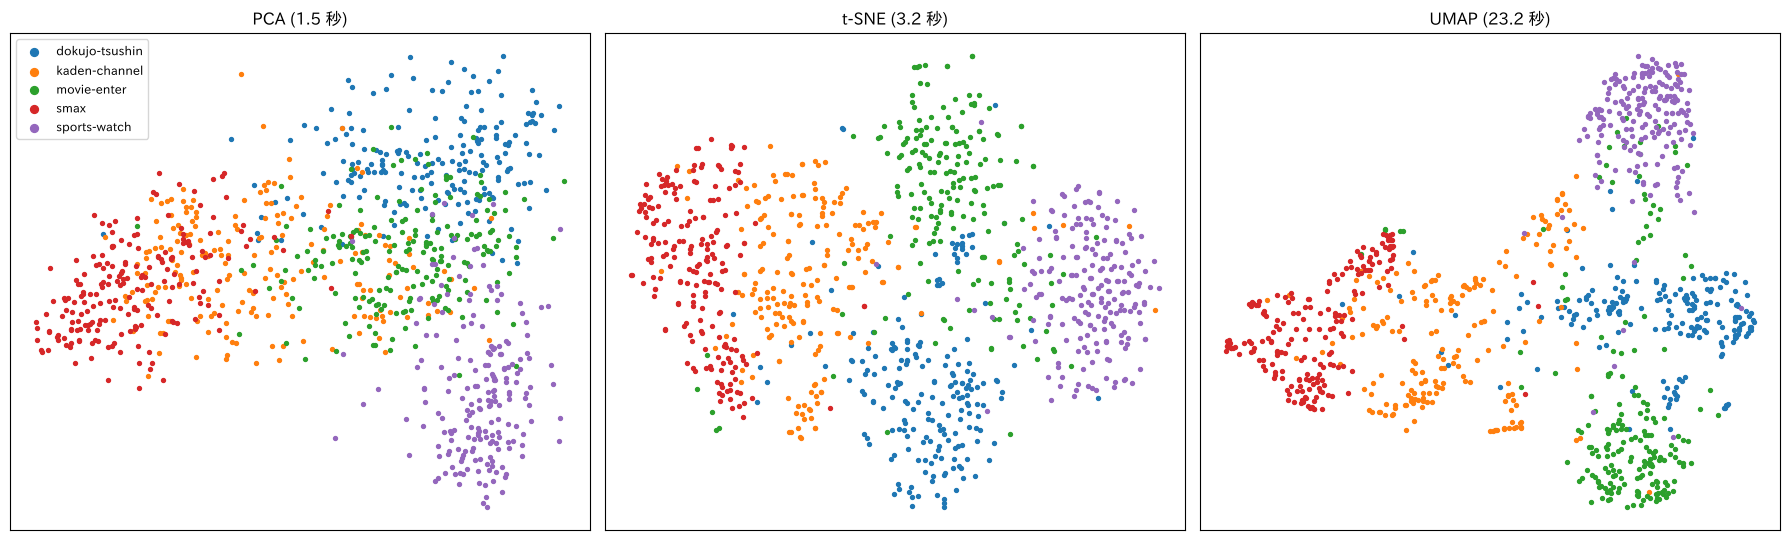

In [3]:
import time
import matplotlib.pyplot as plt
import matplotlib_fontja
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

methods = {
    "PCA": lambda X: PCA(n_components=2, random_state=0).fit_transform(X),
    "t-SNE": lambda X: TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=0).fit_transform(X),
    "UMAP": lambda X: umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=0).fit_transform(X),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
coords = {}
for ax, (name, f) in zip(axes, methods.items()):
    t = time.perf_counter()
    Z = coords[name] = f(emb)
    for label in df["label"].unique():
        m = (df["label"] == label).to_numpy()
        ax.scatter(Z[m, 0], Z[m, 1], s=8, label=label)
    ax.set_title(f"{name} ({time.perf_counter() - t:.1f} 秒)"); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=2, fontsize=9)
plt.tight_layout(); plt.show()

In [4]:
# 2 次元に落としたあとも、元の空間での近傍が保たれているかを数値で比べる (trustworthiness: 1 に近いほど良い)
from sklearn.manifold import trustworthiness
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

pca = PCA(n_components=50, random_state=0).fit(emb)
print(f"PCA: 上位 2 成分の寄与率 {pca.explained_variance_ratio_[:2].sum():.1%}、50 成分で {pca.explained_variance_ratio_.sum():.1%}")
for name, Z in coords.items():
    knn = cross_val_score(KNeighborsClassifier(10), Z, df["label"], cv=5).mean()
    print(f"{name:6} trustworthiness = {trustworthiness(emb, Z, n_neighbors=10, metric='cosine'):.3f}  2 次元での kNN 正解率 = {knn:.3f}")

PCA: 上位 2 成分の寄与率 11.2%、50 成分で 49.8%
PCA    trustworthiness = 0.793  2 次元での kNN 正解率 = 0.724
t-SNE  trustworthiness = 0.923  2 次元での kNN 正解率 = 0.903
UMAP   trustworthiness = 0.908  2 次元での kNN 正解率 = 0.895


- PCA は線形の射影で、軸に意味がある（分散が最大の方向）が、2 次元では情報の大半が落ちる。全体の広がりを見るのに向く。高速で、結果が毎回同じ。
- t-SNE は近い点同士を近くに置くことを重視する。クラスタははっきり見えるが、クラスタ間の距離や大きさには意味がない。`perplexity`（近傍の数の目安）で見え方が変わる。
- UMAP は t-SNE に近い見え方で、大域的な配置も比較的保たれる。件数が多いと t-SNE より速い（図の 23.2 秒は、初回の実行に numba のコンパイルの時間が入るため）。新しい点を後から同じ空間に射影することもできる (`transform`)。
- 5 分割交差検証で計算している「2 次元での kNN 正解率」（k 近傍法）は、データ全体を使って可視化用に射影済みの 2 次元座標 `Z` の上で、2 次元プロット上のクラスタの分離具合を測るための指標であり、未知データに対する下流の分類器としての評価ではない（そもそも t-SNE には未知の点を同じ空間に射影する `transform` がない）。
- どの手法でも、2 次元の図は「眺める」ためのもの。クラスタリングや類似度の計算は、元の高次元のベクトルで行う。
- 点にマウスを載せて原文を見たいなら Plotly: `px.scatter(x=Z[:,0], y=Z[:,1], color=df["label"], hover_name=df["title"])`。